# Musanga NB08 v4_004 — detectability, spatial support, NICFI and forest-condition controls

Existing V3.1 frozen-reference, S2 spectra, pooled-quarter seasonality and native multiscale LOSO work are preserved in Sections 00–10. **New Sections 11–13:** (11) matched 50 m Planet NICFI spectral/texture and embedding-context ablation; (12) independent canopy-height, historical forest-state and tree-cover controls on the available 2019–2020 structure sample; (13) separate UAV DSM surface-roughness sensitivity, explicitly *not* a canopy-height measurement.

**Scientific caveat:** predicting Musanga cover *after controlling for forest condition* is not the same as species-identifying Musanga. The structure controls use earlier-year products, sometimes coarse 100 m tree cover, and the previous screening sampled 25 m neighbourhoods at 50 m cell centres. Controls are useful for assessing **incremental predictive association**, not causal adjustment or precise tree-level height. Planet at Yoko is 2021 versus 2020 UAV acquisition and should be interpreted cautiously.

**Run:** 00–04 to load frozen reference (cached LOFO predictions), then 11–13 directly; Sections 05–10 optional if their cached analysis is already complete. CPU. All experiments use matching complete-case cells for each model comparison and strict 4-forest LOFO, with separate fingerprints and predictions. No Earth Engine, new NICFI extraction or GPU jobs.

## 00 — Configuration and exact cached reference audit

In [1]:
%pip -q install pyarrow scikit-learn scipy pandas matplotlib
from pathlib import Path
import os,json,hashlib,time
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import roc_auc_score,average_precision_score
from scipy.stats import spearmanr
from threadpoolctl import threadpool_limits
from IPython.display import display
from google.colab import drive
if not Path('/content/drive/MyDrive').exists():drive.mount('/content/drive')
threadpool_limits(limits=1)
ROOTS=[
 Path('/content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06'),
 Path('/content/drive/MyDrive/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06')]
found=[p for p in ROOTS if (p/'frozen_50m_reference.parquet').is_file()]
assert len(found)==1,('Expected one existing frozen reference; no new downloads',found)
ROOT=found[0];OUT=ROOT/'17_NB08_V3_1_detectability'
OUT.mkdir(parents=True,exist_ok=True)
D=pd.read_parquet(ROOT/'frozen_50m_reference.parquet')
SITES=('Baego','MOS','Yangambi','Yoko')
KEYS=['site','mosaic','row','col']
assert len(D)==14454 and not D.duplicated(KEYS).any()
assert D.groupby('site').size().to_dict()=={'Baego':480,'MOS':11494,'Yangambi':1383,'Yoko':1097}
assert D.target_fraction.between(0,1).all()
assert {'x','y','target_fraction','site'}.issubset(D.columns)
ANNUAL=sorted(c for c in D if c.startswith('RAW_ANNUAL__'))
QUARTER=sorted(c for c in D if c.startswith('S2_QUARTERLY_3YR__'))
EMB=sorted(c for c in D if c.startswith('EMB_ANNUAL__'))
assert len(ANNUAL)>0 and len(QUARTER)==44 and len(EMB)==64,(len(ANNUAL),len(QUARTER),len(EMB))
# Quarterly clear-observation counts are not spectral reflectance.
Q_COUNTS=[f'S2_QUARTERLY_3YR__{b:02d}' for b in (11,22,33,44)]
assert set(Q_COUNTS).issubset(QUARTER)
S2=[*ANNUAL,*[c for c in QUARTER if c not in Q_COUNTS]]
FEATURE_SETS={'M1_S2':S2,'M2_EMB':EMB,'M3_S2_EMB':[ *S2,*EMB ]}
ALL_FEATURES=sorted(set(sum(FEATURE_SETS.values(),[])))
assert np.isfinite(D[ALL_FEATURES+['target_fraction','x','y']].to_numpy('float32')).all()
assert (D[Q_COUNTS].to_numpy(float)>=1).all(), 'Frozen reference has quarterly no-observation cells; inspect source.'
SEED=20261120
CAP_PER_TRAIN_FOREST=1500
MODEL=dict(learning_rate=.06,max_iter=180,max_leaf_nodes=20,
           min_samples_leaf=35,l2_regularization=2,early_stopping=False)
THRESHOLDS=(.05,.20,.40)
# Compute fingerprints once; do not overwrite unrelated historical outputs.
SOURCE_SHA=hashlib.sha256(pd.util.hash_pandas_object(
 D[KEYS+['x','y','target_fraction']+ALL_FEATURES],index=False).values.tobytes()).hexdigest()
CONFIG={'version':'NB08_V3_1_LOFO_detectability_v4_001','sites':SITES,
 'n':len(D),'features':{k:len(v) for k,v in FEATURE_SETS.items()},
 'seed':SEED,'cap':CAP_PER_TRAIN_FOREST,'model':MODEL,
 'thresholds':THRESHOLDS,'source_sha256':SOURCE_SHA}
SIGNATURE=hashlib.sha256(json.dumps(CONFIG,sort_keys=True).encode()).hexdigest()[:14]
RUN=OUT/SIGNATURE;RUN.mkdir(parents=True,exist_ok=True)
config_path=RUN/'config.json'
if config_path.is_file():assert json.loads(config_path.read_text())==json.loads(json.dumps(CONFIG))
else:config_path.write_text(json.dumps(CONFIG,indent=2))
print('Source:',ROOT/'frozen_50m_reference.parquet')
print('Saved outputs:',RUN,'| signature:',SIGNATURE)
display(D.groupby('site').target_fraction.agg(n='size',mean='mean',std='std',maximum='max').round(3))
print('Predictors: S2 annual',len(ANNUAL),'+ quarterly reflectance',len(QUARTER)-len(Q_COUNTS),'; embeddings',len(EMB))
print('No imagery downloads or raster reads are required.')


Mounted at /content/drive
Source: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06/frozen_50m_reference.parquet
Saved outputs: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06/17_NB08_V3_1_detectability/53e2223ba398c6 | signature: 53e2223ba398c6


,n,mean,std,maximum
site,,,,
Baego,480,0.172,0.169,0.945
MOS,11494,0.200,0.165,0.926
Yangambi,1383,0.048,0.038,0.360
Yoko,1097,0.132,0.134,0.854


Predictors: S2 annual 15 + quarterly reflectance 40 ; embeddings 64
No imagery downloads or raster reads are required.


## 01 — A strict, small, cached leave-one-forest-out experiment

Use the original V3.1 source's **balanced-by-forest and cover-stratum** training principle; training selections depend only on training-forest targets. Each held-out forest is untouched until scoring. Single-model fits are intended as a first detectability test rather than hyperparameter optimization.

In [2]:
y=D.target_fraction.to_numpy(np.float32)
site=D.site.to_numpy()
def balanced_draw(pool,heldout):
 rng=np.random.default_rng(SEED+sum(map(ord,heldout)))
 chosen=[]
 for forest in SITES:
  ix=pool[site[pool]==forest]
  if not len(ix):continue
  cap=min(len(ix),CAP_PER_TRAIN_FOREST)
  if len(ix)<=cap:
   chosen.extend(ix.tolist());continue
  strata=np.digitize(y[ix],[.10,.20,.40])
  bins={j:ix[strata==j] for j in range(4)}
  pick=[]
  # Keep up to a quarter of training sample above 40% where available.
  take=min(len(bins[3]),int(np.ceil(.25*cap)))
  if take:
   ids=rng.choice(bins[3],take,replace=False)
   pick.extend(ids.tolist());bins[3]=np.setdiff1d(bins[3],ids)
  while len(pick)<cap:
   active=[k for k in bins if len(bins[k])]
   assert active
   for k in active:
    n=min(len(bins[k]),max(1,(cap-len(pick))//len(active)),cap-len(pick))
    if n>0:
     ids=rng.choice(bins[k],n,replace=False)
     pick.extend(ids.tolist());bins[k]=np.setdiff1d(bins[k],ids)
    if len(pick)>=cap:break
  chosen.extend(pick)
 return np.asarray(sorted(chosen),dtype=int)
predictions=[]
audit=[]
for held in SITES:
 test=np.flatnonzero(site==held)
 train_pool=np.flatnonzero(site!=held)
 train=balanced_draw(train_pool,held)
 assert not np.intersect1d(train,test).size
 audit.append(dict(heldout=held,train_cells=len(train),test_cells=len(test),
                   high_train=int((y[train]>=.40).sum())))
 # The constant null is learned from the **same** training draw.
 null_value=float(np.mean(y[train]))
 frame=D.iloc[test][KEYS+['x','y','target_fraction']].copy().reset_index(drop=True)
 frame['heldout']=held
 frame['M0_mean']=null_value
 for model_name,cols in FEATURE_SETS.items():
  cache=RUN/f'{held}_{model_name}.npz'
  if cache.is_file():
   with np.load(cache,allow_pickle=False) as z:
    assert np.array_equal(z['test_index'],test)
    assert z['source_sha256'].item()==SOURCE_SHA
    pred=z['pred'].astype(np.float32)
   print('CACHE',held,model_name,flush=True)
  else:
   t=time.monotonic()
   model=HistGradientBoostingRegressor(random_state=SEED,**MODEL)
   model.fit(D.iloc[train][cols].to_numpy('float32'),y[train])
   pred=np.clip(model.predict(D.iloc[test][cols].to_numpy('float32')),0,1).astype(np.float32)
   tmp=cache.with_suffix('.partial')
   with open(tmp,'wb') as f:
    np.savez_compressed(f,test_index=test,pred=pred,source_sha256=SOURCE_SHA)
   os.replace(tmp,cache)
   print('FIT',held,model_name,'seconds',round(time.monotonic()-t,1),flush=True)
  frame[model_name]=pred
 predictions.append(frame)
P=pd.concat(predictions,ignore_index=True)
assert len(P)==len(D) and not P.duplicated(KEYS).any()
assert P[['M0_mean',*FEATURE_SETS]].notna().all().all()
P.to_parquet(RUN/'01_paired_LOFO_predictions.parquet',index=False)
pd.DataFrame(audit).to_csv(RUN/'01_training_fold_sizes.csv',index=False)
display(pd.DataFrame(audit))
print('All held-out predictions cached on the same 14,454 frozen reference cells.')


CACHE Baego M1_S2
CACHE Baego M2_EMB
CACHE Baego M3_S2_EMB
CACHE MOS M1_S2
CACHE MOS M2_EMB
CACHE MOS M3_S2_EMB
CACHE Yangambi M1_S2
CACHE Yangambi M2_EMB
CACHE Yangambi M3_S2_EMB
CACHE Yoko M1_S2
CACHE Yoko M2_EMB
CACHE Yoko M3_S2_EMB


,heldout,train_cells,test_cells,high_train
0,Baego,3980,480,610
1,MOS,2960,11494,119
2,Yangambi,3077,1383,667
3,Yoko,3363,1097,605


All held-out predictions cached on the same 14,454 frozen reference cells.


## 02 — Forest-equal continuous-cover prediction and abundance detection

Use per-forest equal-weight metrics, never global pixel weighting that allows MOS to dominate. Continuous regression: R², MAE, RMSE, bias and Spearman. For thresholds 5%, 20%, 40%, compute ROC-AUC and average precision from **continuous prediction scores**, plus prevalence and a training-derived constant-score baseline. Undefined AUC for missing positive or negative classes is reported as NaN (not zero).

In [3]:
MODELS=['M0_mean',*FEATURE_SETS]
def metrics(g,col):
 obs=g.target_fraction.to_numpy(float)
 pred=g[col].to_numpy(float)
 err=pred-obs
 var=float(np.mean((obs-np.mean(obs))**2))
 rho=spearmanr(obs,pred).statistic if np.std(pred)>1e-12 and np.std(obs)>1e-12 else np.nan
 return dict(n=len(g),R2=float(1-np.mean(err**2)/var) if var>0 else np.nan,
             MAE_pp=float(100*np.mean(np.abs(err))),
             RMSE_pp=float(100*np.sqrt(np.mean(err**2))),
             bias_pp=float(100*np.mean(err)),
             spearman_rho=float(rho) if np.isfinite(rho) else np.nan)
PER=pd.DataFrame([dict(site=forest,model=model,**metrics(g,model))
 for forest,g in P.groupby('site') for model in MODELS])
PER.to_csv(RUN/'02_continuous_by_forest.csv',index=False)
SUMMARY=[]
for model in MODELS:
 sub=PER[PER.model.eq(model)]
 # Global equal-forest R² with pooled equal-forest target variance.
 means=P.groupby('site').target_fraction.mean()
 v=np.mean([np.mean((g.target_fraction-means[s])**2)+(means[s]-means.mean())**2
      for s,g in P.groupby('site')])
 mse=np.mean([np.mean((g[model]-g.target_fraction)**2) for s,g in P.groupby('site')])
 SUMMARY.append(dict(model=model,n_cells=len(P),n_forests=len(SITES),
  equal_forest_R2=float(1-mse/v) if v>0 else np.nan,
  equal_forest_MAE_pp=float(sub.MAE_pp.mean()),
  equal_forest_RMSE_pp=float(np.sqrt(np.mean(sub.RMSE_pp**2))),
  equal_forest_bias_pp=float(sub.bias_pp.mean()),
  mean_forest_rho=float(sub.spearman_rho.mean())))
SUMMARY=pd.DataFrame(SUMMARY)
SUMMARY.to_csv(RUN/'02_equal_forest_summary.csv',index=False)
DISC=[]
for (forest,model),g in (( (f,m),q) for f,q in P.groupby('site') for m in MODELS):
 obs=g.target_fraction.to_numpy(float)
 pred=g[model].to_numpy(float)
 for t in THRESHOLDS:
  true=(obs>=t).astype(int)
  npos=int(true.sum());nneg=len(true)-npos
  auc=roc_auc_score(true,pred) if npos and nneg and np.unique(pred).size>1 else np.nan
  ap=average_precision_score(true,pred) if npos and nneg else np.nan
  DISC.append(dict(site=forest,model=model,threshold=t,
       n=len(g),positive_n=npos,negative_n=nneg,
       prevalence=npos/len(g),ROC_AUC=auc,average_precision=ap))
DISC=pd.DataFrame(DISC)
DISC.to_csv(RUN/'02_abundance_detection_by_forest.csv',index=False)
DISPLAY_DISC=(DISC.groupby(['model','threshold']).agg(
 n_forests_evaluable=('ROC_AUC','count'),
 mean_AUC=('ROC_AUC','mean'),
 mean_AP=('average_precision','mean'),
 mean_prevalence=('prevalence','mean')).reset_index())
DISPLAY_DISC.to_csv(RUN/'02_equal_forest_detection_summary.csv',index=False)
print('Equal-forest continuous-cover scores:')
display(SUMMARY.round(3))
print('Abundance discrimination (undefined sites omitted, counts explicit):')
display(DISPLAY_DISC.round(3))
print('Important: high-cover detection is undefined for forests without high-cover examples.')


Equal-forest continuous-cover scores:


,model,n_cells,n_forests,equal_forest_R2,equal_forest_MAE_pp,equal_forest_RMSE_pp,equal_forest_bias_pp,mean_forest_rho
0,M0_mean,14454,4,-0.288,13.479,16.861,2.165,NaN
1,M1_S2,14454,4,0.495,7.672,10.556,1.731,0.533
2,M2_EMB,14454,4,0.390,8.445,11.600,2.499,0.562
3,M3_S2_EMB,14454,4,0.513,7.414,10.365,2.018,0.611


Abundance discrimination (undefined sites omitted, counts explicit):


,model,threshold,n_forests_evaluable,mean_AUC,mean_AP,mean_prevalence
0,M0_mean,0.05,0,NaN,0.664,0.664
1,M0_mean,0.20,0,NaN,0.227,0.227
2,M0_mean,0.40,0,NaN,0.100,0.075
3,M1_S2,0.05,4,0.723,0.812,0.664
4,M1_S2,0.20,4,0.894,0.653,0.227
5,M1_S2,0.40,3,0.898,0.573,0.075
6,M2_EMB,0.05,4,0.752,0.821,0.664
7,M2_EMB,0.20,4,0.873,0.589,0.227
8,M2_EMB,0.40,3,0.887,0.513,0.075
9,M3_S2_EMB,0.05,4,0.773,0.837,0.664


Important: high-cover detection is undefined for forests without high-cover examples.


## 03 — Visual evidence: spectral contrasts, held-out predictions and detectability

**Figure A:** within-forest low vs high cover spectral contrast on the frozen 50 m cells; avoids visually conflating broad differences among forests. Spectral columns are raw annual source bands (band numbers until independently verified); do not claim wavelengths without an audited metadata lookup.

**Figure B:** held-out continuous fractional cover by forest, preserving the four-fold transfer test.

**Figure C:** abundance discrimination curves at 5, 20 and 40% (mean of evaluable forests, number of evaluable forests displayed).

Spectral contrast not estimable Yangambi low 894 high 0


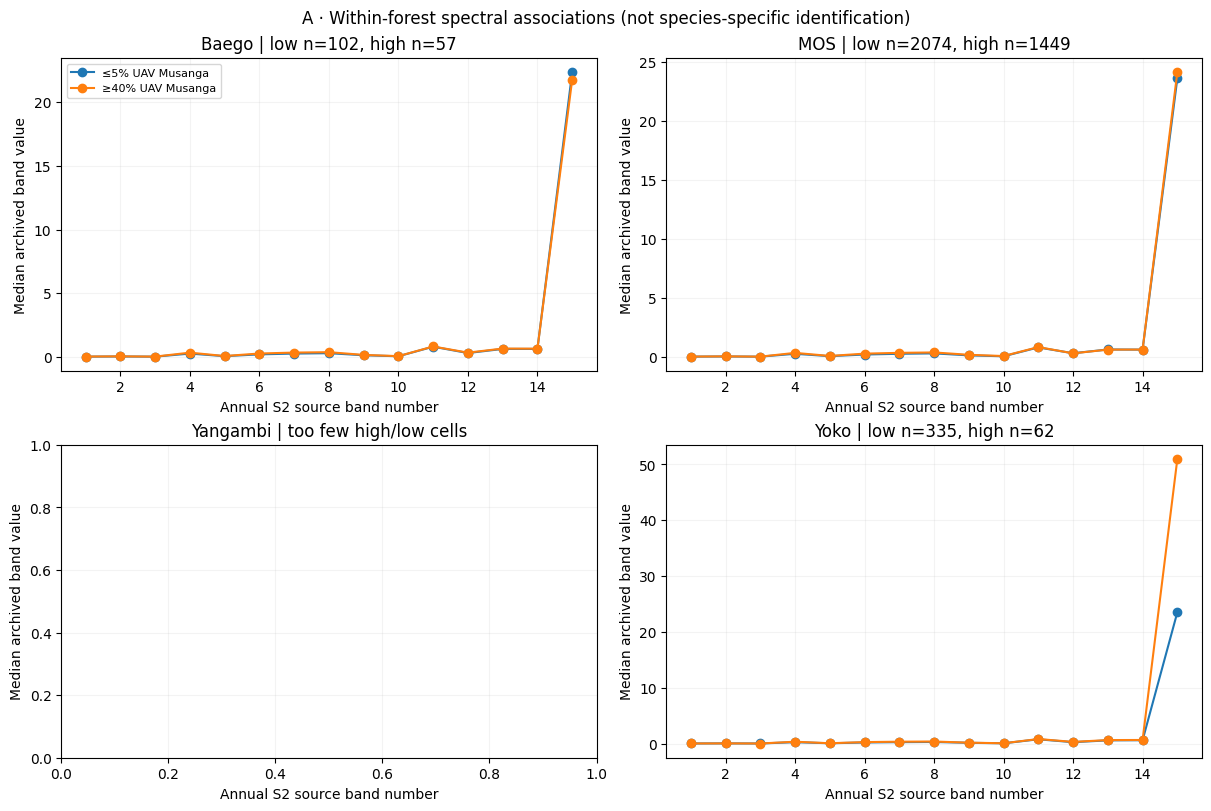

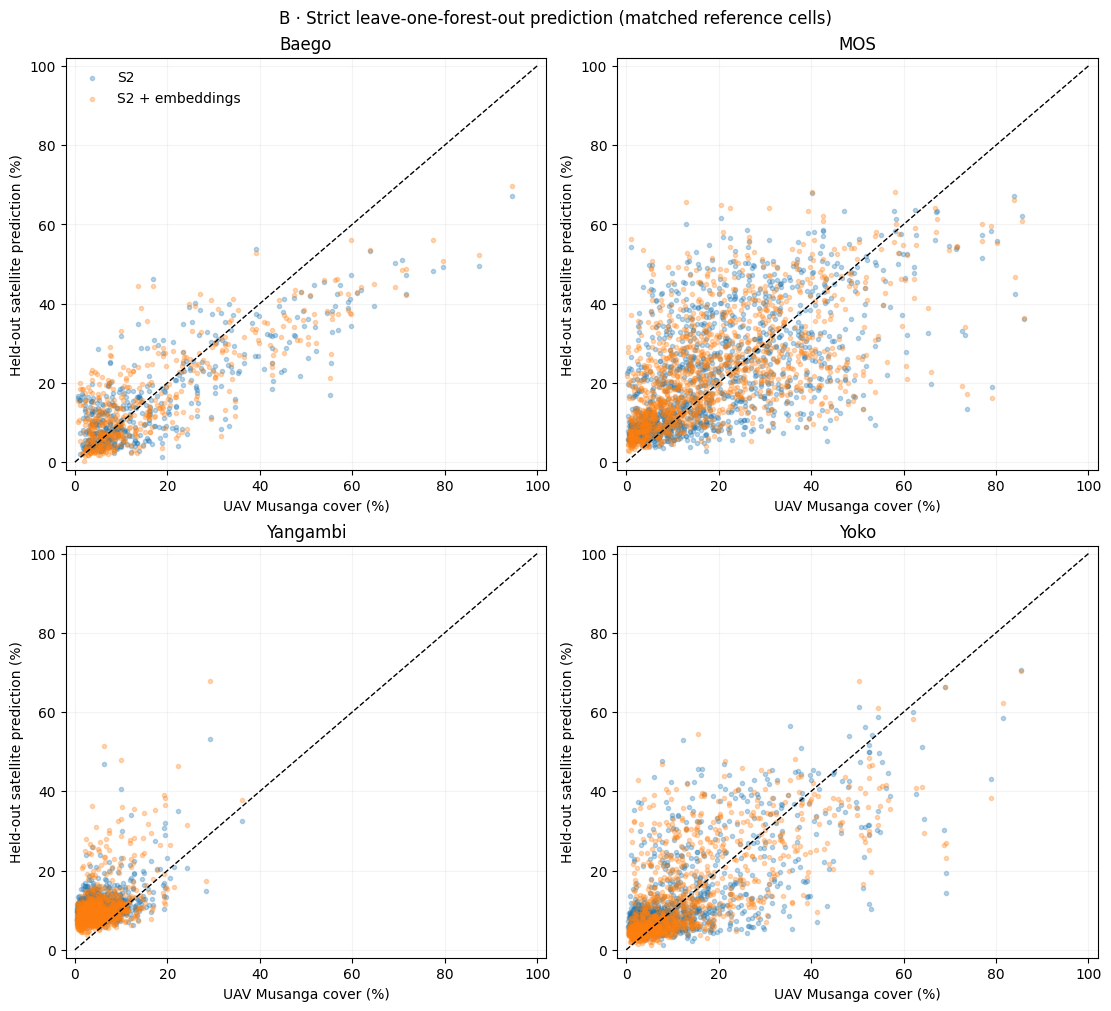

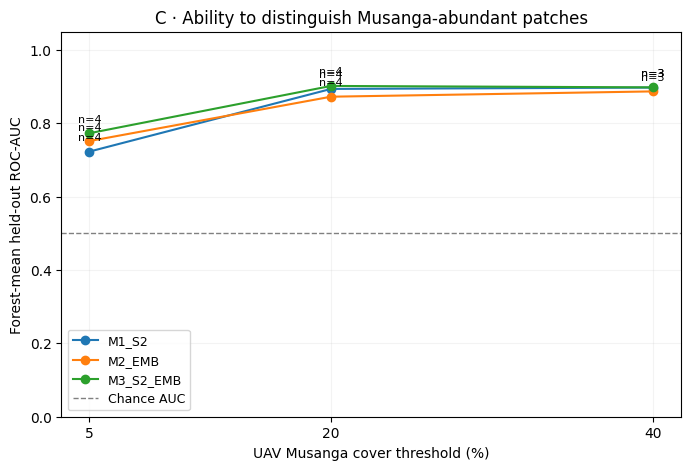

Three figures saved: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06/17_NB08_V3_1_detectability/53e2223ba398c6


In [4]:
import matplotlib
from matplotlib.lines import Line2D
# A: Within-forest annual S2 contrast. Use percentiles for robustness.
low=.05;high=.40
rows=[]
for forest,g in D.groupby('site'):
 lo=g[g.target_fraction<=low]
 hi=g[g.target_fraction>=high]
 if len(lo)<10 or len(hi)<10:
  print('Spectral contrast not estimable',forest,'low',len(lo),'high',len(hi));continue
 for i,c in enumerate(ANNUAL,1):
  lv=float(lo[c].median());hv=float(hi[c].median())
  rows.append(dict(site=forest,band=c,band_order=i,n_low=len(lo),
                   n_high=len(hi),median_low=lv,median_high=hv,
                   difference=hv-lv))
SPECTRA=pd.DataFrame(rows)
SPECTRA.to_csv(RUN/'03_within_forest_annual_S2_spectra.csv',index=False)
fig,axs=plt.subplots(2,2,figsize=(12,8),layout='constrained')
for ax,forest in zip(axs.flat,SITES):
 g=SPECTRA[SPECTRA.site.eq(forest)]
 if len(g):
  ax.plot(g.band_order,g.median_low,'o-',label='≤5% UAV Musanga')
  ax.plot(g.band_order,g.median_high,'o-',label='≥40% UAV Musanga')
  ax.set_title(f'{forest} | low n={g.n_low.iloc[0]}, high n={g.n_high.iloc[0]}')
 else:
  ax.set_title(f'{forest} | too few high/low cells')
 ax.set(xlabel='Annual S2 source band number',ylabel='Median archived band value')
 ax.grid(alpha=.15)
axs.flat[0].legend(fontsize=8)
fig.suptitle('A · Within-forest spectral associations (not species-specific identification)')
fig.savefig(RUN/'03A_S2_within_forest_low_high_spectra.png',dpi=170,bbox_inches='tight')
plt.show();plt.close(fig)
# B: For each forest show S2 vs embeddings+S2; cap plots only, not metrics.
fig,axs=plt.subplots(2,2,figsize=(11,10),layout='constrained')
for ax,forest in zip(axs.flat,SITES):
 g=P[P.site.eq(forest)].copy()
 if len(g)>1300:g=g.sample(n=1300,random_state=SEED)
 ax.scatter(g.target_fraction*100,g.M1_S2*100,s=9,alpha=.3,label='S2')
 ax.scatter(g.target_fraction*100,g.M3_S2_EMB*100,s=9,alpha=.3,label='S2 + embeddings')
 ax.plot([0,100],[0,100],'k--',lw=1)
 ax.set(title=forest,xlabel='UAV Musanga cover (%)',
        ylabel='Held-out satellite prediction (%)',
        xlim=(-2,102),ylim=(-2,102))
 ax.grid(alpha=.15)
axs.flat[0].legend(frameon=False)
fig.suptitle('B · Strict leave-one-forest-out prediction (matched reference cells)')
fig.savefig(RUN/'03B_heldout_scatter_by_forest.png',dpi=180,bbox_inches='tight')
plt.show();plt.close(fig)
# C: Mean AUC by cover threshold and number of forests actually evaluable.
fig,ax=plt.subplots(figsize=(8,5))
for model in MODELS[1:]:
 q=DISPLAY_DISC[DISPLAY_DISC.model.eq(model)].sort_values('threshold')
 ax.plot(q.threshold*100,q.mean_AUC,marker='o',label=model)
 for v in q.itertuples():
  if np.isfinite(v.mean_AUC):
   ax.annotate(f'n={v.n_forests_evaluable}',(v.threshold*100,v.mean_AUC),
               xytext=(0,8),textcoords='offset points',ha='center',fontsize=8)
ax.axhline(.5,ls='--',color='gray',lw=1,label='Chance AUC')
ax.set(xlabel='UAV Musanga cover threshold (%)',ylabel='Forest-mean held-out ROC-AUC',
       ylim=(0,1.05),xticks=[5,20,40],
       title='C · Ability to distinguish Musanga-abundant patches')
ax.legend(fontsize=9);ax.grid(alpha=.15)
fig.savefig(RUN/'03C_abundance_discrimination.png',dpi=180,bbox_inches='tight')
plt.show();plt.close(fig)
print('Three figures saved:',RUN)


## 04 — Compact decision and caveats

Interpret performance for **all four forests**, not just the pooled R². Compare M1 vs M0 (satellite information); M2 vs M1 (embeddings versus raw S2); and M3 vs both. AUC > 0.5 on evaluable, held-out forests supports **association**, not Musanga-specific spectral identifiability. Inspect forest abundance prevalence: at >40% the Yangambi fold has no positives, so the ROC-AUC is not defined.

**Caveats:** frozen V3.1 labels derive from an earlier UAV model; pixel-neighbour dependence invalidates naive cell-wise confidence intervals. Sampling to balance training forests is fixed, not evaluated as an optimal algorithm. The threshold experiment uses continuous regression scores—not binary models—avoiding separate threshold-fitting. Do not interpret within-forest band profiles as independent species spectra; examine confounding by young forest and disturbance in a later experiment.

**Next iteration:** once NB07 V4 RGB+MS inference is complete, reaggregate its valid-pixel predictions to the exact 50 m satellite cells, keep a matched validity mask, and repeat the same fixed experiment. Do not mix V3.1 and V4 targets in a single score.

In [5]:
manifest={'experiment':'NB08_v4_001_V3_1','input':str(ROOT/'frozen_50m_reference.parquet'),
 'source_sha256':SOURCE_SHA,'signature':SIGNATURE,
 'n_reference_cells':len(D),'n_sites':len(SITES),
 'feature_families':{k:len(v) for k,v in FEATURE_SETS.items()},
 'spatial_validation':'leave_one_forest_out',
 'reference':'V3_1 UAV teacher-derived fractional Musanga cover',
 'warning':'Predictive association is not species-unique identification',
 'outputs':str(RUN)}
(RUN/'04_run_manifest.json').write_text(json.dumps(manifest,indent=2))
print('NB08 V3.1 detection experiment completed:',RUN)
print('Primary output: 02_equal_forest_summary.csv')
print('Detection output: 02_equal_forest_detection_summary.csv')
print('Paired predictions: 01_paired_LOFO_predictions.parquet')


NB08 V3.1 detection experiment completed: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06/17_NB08_V3_1_detectability/53e2223ba398c6
Primary output: 02_equal_forest_summary.csv
Detection output: 02_equal_forest_detection_summary.csv
Paired predictions: 01_paired_LOFO_predictions.parquet


## 05 — Proper Sentinel-2 spectra and seasonal separability

Plot only reflectance bands at their physical wavelength locations, not NDVI/NDMI/counts. Within each forest, compare ≤5% versus ≥40% cover, showing IQR and effect sizes. Quarterly columns are arranged 10 reflectance channels + 1 count for each pooled 3-year quarter. These are not monthly observations.

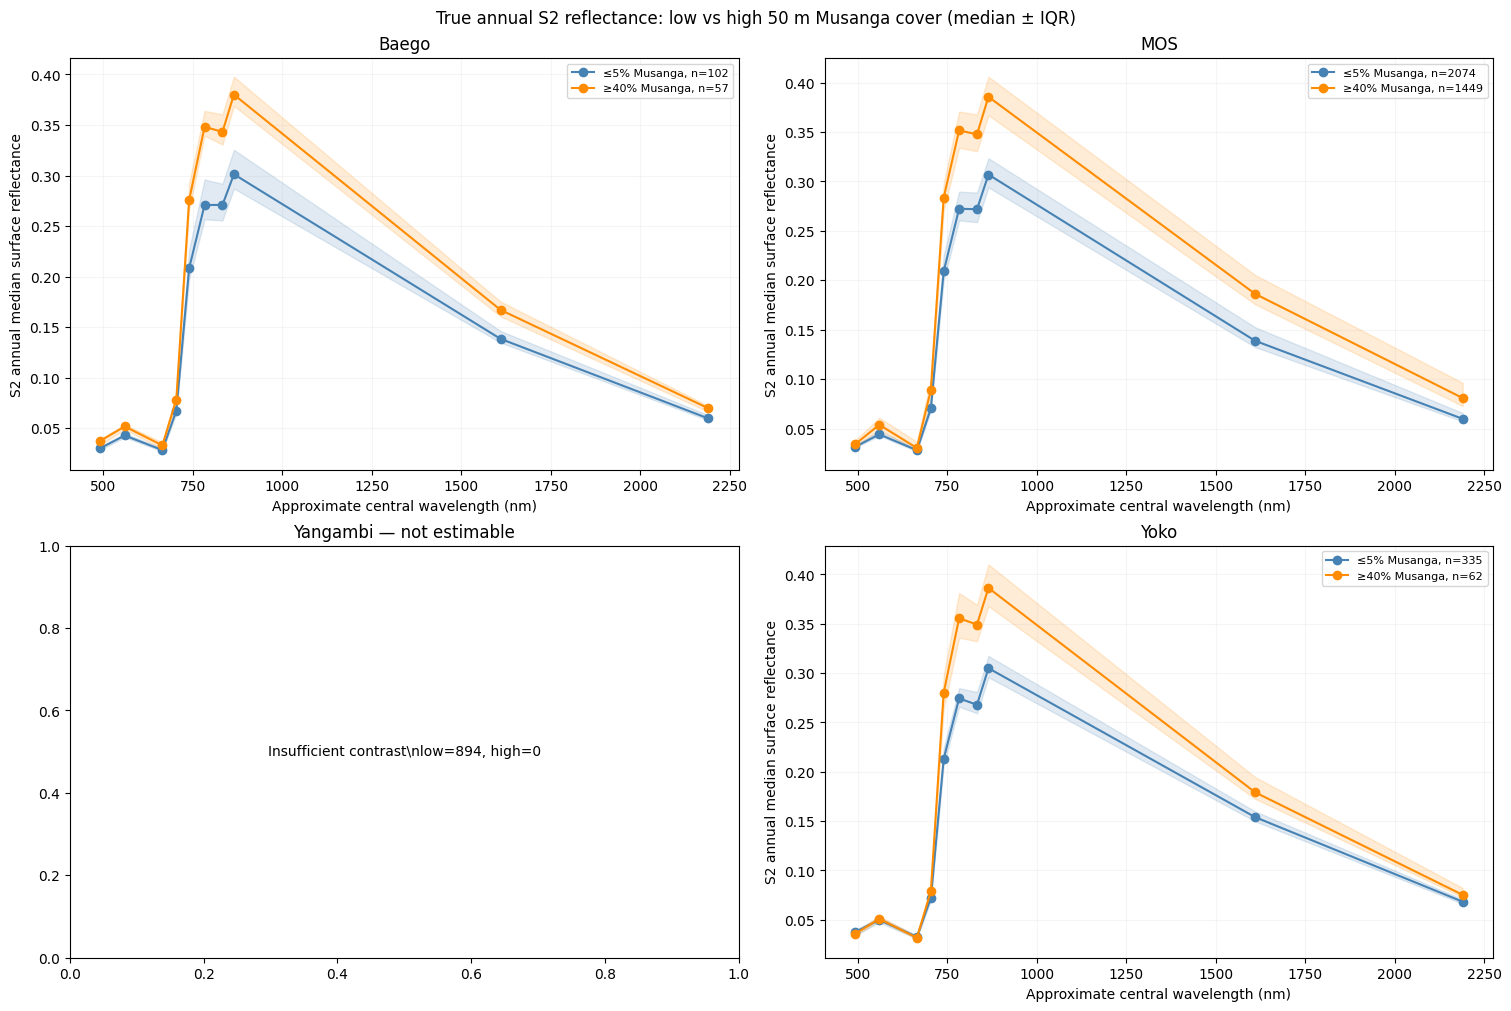

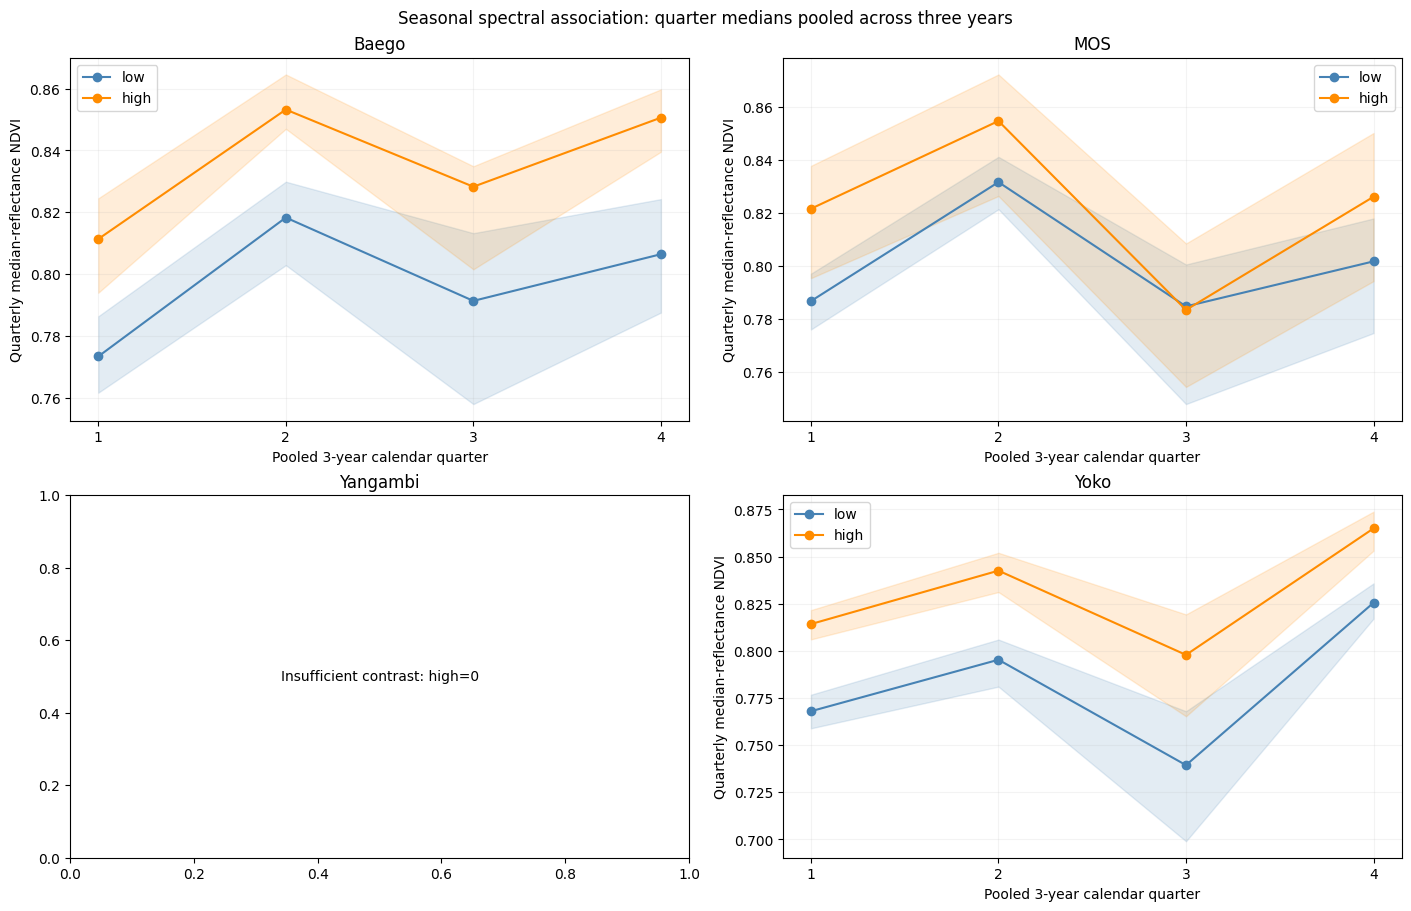

Spectral plots complete. Overlap of distributions is expected in mixed 50 m canopies.


In [6]:
# 10 original annual reflectance bands (verified upstream Earth Engine selection order)
S2_BANDS=['B2','B3','B4','B8','B5','B6','B7','B8A','B11','B12']
S2_WAVELENGTH_NM=np.array([492,560,665,833,704,740,783,865,1610,2190])
S2_ORDER=np.argsort(S2_WAVELENGTH_NM)
assert len(ANNUAL)==15 and len(QUARTER)==44
REFLECTANCE=[f'RAW_ANNUAL__{i:02d}' for i in range(1,11)]
INDICES=[f'RAW_ANNUAL__{i:02d}' for i in range(11,15)]
CLEAR_ANNUAL='RAW_ANNUAL__15'
Q_REFLECTANCE={q:[f'S2_QUARTERLY_3YR__{(q-1)*11+i:02d}' for i in range(1,11)] for q in range(1,5)}
assert set(REFLECTANCE+INDICES+[CLEAR_ANNUAL])==set(ANNUAL)
assert set(sum(Q_REFLECTANCE.values(),[])+Q_COUNTS)==set(QUARTER)
# Plot median and interquartile envelope of raw reflectance; no modelling in this block.
spectral_rows=[]
fig,axarr=plt.subplots(2,2,figsize=(15,10),layout='constrained')
for ax,forest in zip(axarr.flat,SITES):
 g=D[D.site.eq(forest)]
 low=g[g.target_fraction<=.05];high=g[g.target_fraction>=.40]
 if len(high)<10 or len(low)<10:
  ax.text(.5,.5,f'Insufficient contrast\\nlow={len(low)}, high={len(high)}',
          ha='center',va='center',transform=ax.transAxes)
  ax.set_title(f'{forest} — not estimable')
  continue
 for subset,label,color in [(low,'≤5% Musanga','steelblue'),(high,'≥40% Musanga','darkorange')]:
  arr=subset[REFLECTANCE].to_numpy(float)[:,S2_ORDER]
  wl=S2_WAVELENGTH_NM[S2_ORDER]
  med=np.median(arr,axis=0);q25=np.percentile(arr,25,axis=0);q75=np.percentile(arr,75,axis=0)
  ax.plot(wl,med,'o-',label=f'{label}, n={len(subset)}',color=color)
  ax.fill_between(wl,q25,q75,alpha=.16,color=color)
  for j,k in enumerate(S2_ORDER):
   spectral_rows.append(dict(site=forest,group=label,band=S2_BANDS[k],
     wavelength_nm=int(S2_WAVELENGTH_NM[k]),n=len(subset),
     median=float(med[j]),q25=float(q25[j]),q75=float(q75[j])))
 ax.set(xlabel='Approximate central wavelength (nm)',
        ylabel='S2 annual median surface reflectance',title=forest)
 ax.legend(fontsize=8);ax.grid(alpha=.12)
fig.suptitle('True annual S2 reflectance: low vs high 50 m Musanga cover (median ± IQR)')
fig.savefig(RUN/'05A_annual_S2_true_reflectance_IQR.png',dpi=180)
plt.show();plt.close(fig)
pd.DataFrame(spectral_rows).to_csv(RUN/'05A_annual_S2_true_reflectance_IQR.csv',index=False)
# Seasonal reflectance: 3-year pooled quarter medians, NOT single-year snapshots.
seasonal_rows=[]
fig,axarr=plt.subplots(2,2,figsize=(14,9),layout='constrained')
for ax,forest in zip(axarr.flat,SITES):
 g=D[D.site.eq(forest)]
 low=g[g.target_fraction<=.05];high=g[g.target_fraction>=.40]
 if len(high)<10 or len(low)<10:
  ax.text(.5,.5,f'Insufficient contrast: high={len(high)}',ha='center',va='center',transform=ax.transAxes)
  ax.set_title(forest);continue
 for q in range(1,5):
  for subset,name in [(low,'low'),(high,'high')]:
   # NDVI is computed from quarter median reflectances (B8 = index 4; B4 = index 3).
   nir=subset[Q_REFLECTANCE[q][3]].to_numpy(float)
   red=subset[Q_REFLECTANCE[q][2]].to_numpy(float)
   ndvi=(nir-red)/np.maximum(nir+red,1e-8)
   med=float(np.median(ndvi))
   seasonal_rows.append(dict(site=forest,quarter=q,class_name=name,
                              n=len(subset),median_NDVI=med,
                              q25_NDVI=float(np.percentile(ndvi,25)),
                              q75_NDVI=float(np.percentile(ndvi,75))))
 for name,color in [('low','steelblue'),('high','darkorange')]:
  a=pd.DataFrame(seasonal_rows)
  a=a[(a.site==forest)&(a.class_name==name)].sort_values('quarter')
  ax.plot(a.quarter,a.median_NDVI,'o-',color=color,label=name)
  ax.fill_between(a.quarter.to_numpy(float),a.q25_NDVI.to_numpy(float),
                  a.q75_NDVI.to_numpy(float),alpha=.15,color=color)
 ax.set(title=forest,xlabel='Pooled 3-year calendar quarter',ylabel='Quarterly median-reflectance NDVI',
        xticks=[1,2,3,4])
 ax.grid(alpha=.15);ax.legend()
fig.suptitle('Seasonal spectral association: quarter medians pooled across three years')
fig.savefig(RUN/'05B_pooled_quarterly_NDVI_IQR.png',dpi=180)
plt.show();plt.close(fig)
pd.DataFrame(seasonal_rows).to_csv(RUN/'05B_pooled_quarterly_NDVI_IQR.csv',index=False)
print('Spectral plots complete. Overlap of distributions is expected in mixed 50 m canopies.')


## 06 — Why does Sentinel-2 predict so well? LOFO annual-versus-seasonal ablation

This isolates single-year reflectance, four annual indices, and 3-year pooled quarterly reflectance. Identical targets, same training draws (from Section 01), same holdouts and model hyperparameters. It does **not** infer phenological mechanisms from predictive performance alone. All metrics are computed with equal weight for each forest.

CACHE Baego A_reflectance_only
CACHE Baego B_annual_plus_indices
CACHE Baego C_pooled_quarters_only
CACHE Baego D_annual_plus_quarters
CACHE Baego E_embeddings_only
CACHE Baego F_all_plus_embeddings
CACHE MOS A_reflectance_only
CACHE MOS B_annual_plus_indices
CACHE MOS C_pooled_quarters_only
CACHE MOS D_annual_plus_quarters
CACHE MOS E_embeddings_only
CACHE MOS F_all_plus_embeddings
CACHE Yangambi A_reflectance_only
CACHE Yangambi B_annual_plus_indices
CACHE Yangambi C_pooled_quarters_only
CACHE Yangambi D_annual_plus_quarters
CACHE Yangambi E_embeddings_only
CACHE Yangambi F_all_plus_embeddings
CACHE Yoko A_reflectance_only
CACHE Yoko B_annual_plus_indices
CACHE Yoko C_pooled_quarters_only
CACHE Yoko D_annual_plus_quarters
CACHE Yoko E_embeddings_only
CACHE Yoko F_all_plus_embeddings


,variant,n_forests,mean_MAE_pp,equal_forest_R2,equal_forest_RMSE_pp,mean_bias_pp
0,A_reflectance_only,4,7.683,0.501,10.489,1.654
1,B_annual_plus_indices,4,7.498,0.516,10.329,1.202
2,C_pooled_quarters_only,4,8.466,0.380,11.695,2.754
3,D_annual_plus_quarters,4,7.605,0.498,10.523,1.808
4,E_embeddings_only,4,8.445,0.390,11.600,2.499
5,F_all_plus_embeddings,4,7.392,0.501,10.490,1.981


variant,A_reflectance_only,B_annual_plus_indices,C_pooled_quarters_only,D_annual_plus_quarters,E_embeddings_only,F_all_plus_embeddings
site,,,,,,
Baego,7.88,7.81,7.07,6.90,6.97,7.08
MOS,9.92,9.62,12.01,10.31,9.93,10.28
Yangambi,5.86,5.69,7.16,6.15,8.16,5.04
Yoko,7.06,6.86,7.62,7.06,8.72,7.16


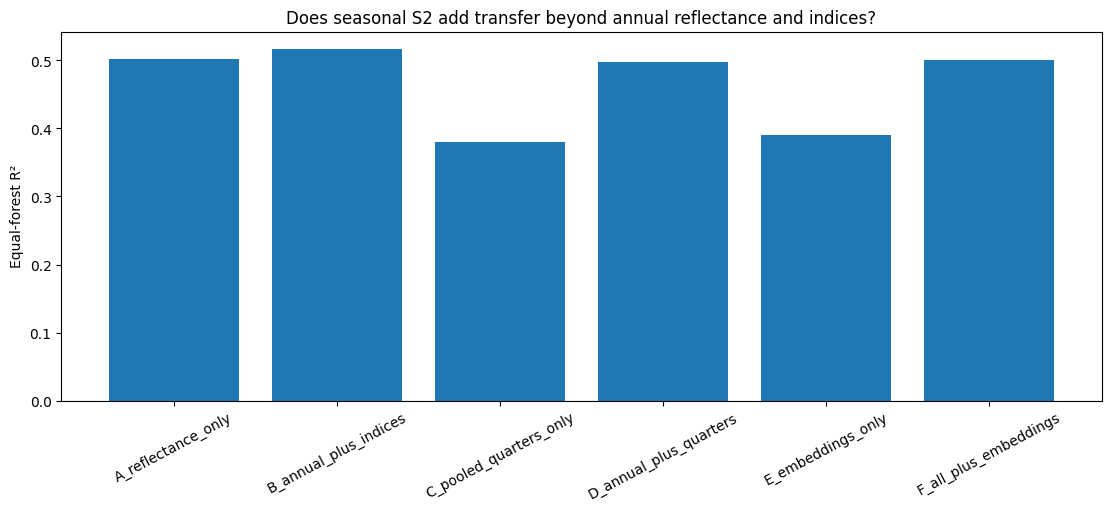

Annual-versus-seasonal LOFO results: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06/17_NB08_V3_1_detectability/18_S2_temporal_ablation/1b80d1bf1a9e


In [7]:
ABLATION={
 'A_reflectance_only':REFLECTANCE,
 'B_annual_plus_indices':REFLECTANCE+INDICES,
 'C_pooled_quarters_only':sum(Q_REFLECTANCE.values(),[]),
 'D_annual_plus_quarters':REFLECTANCE+INDICES+sum(Q_REFLECTANCE.values(),[]),
 'E_embeddings_only':EMB,
 'F_all_plus_embeddings':REFLECTANCE+INDICES+sum(Q_REFLECTANCE.values(),[])+EMB
}
ABL_CFG={'version':'NB08_S2_temporal_ablation_v1','seed':SEED,'model':MODEL,
        'train_cap':CAP_PER_TRAIN_FOREST,'features':ABLATION,
        'source':SOURCE_SHA}
ABL_ID=hashlib.sha256(json.dumps(ABL_CFG,sort_keys=True).encode()).hexdigest()[:12]
ABL_DIR=OUT/'18_S2_temporal_ablation'/ABL_ID
ABL_DIR.mkdir(parents=True,exist_ok=True)
(ABL_DIR/'config.json').write_text(json.dumps(ABL_CFG,indent=2))
rows=[];pred_frames=[]
for forest in SITES:
 test=np.flatnonzero(site==forest)
 train=balanced_draw(np.flatnonzero(site!=forest),forest)
 part=D.iloc[test][KEYS+['target_fraction']].copy().reset_index(drop=True)
 for variant,features in ABLATION.items():
  cache=ABL_DIR/f'{forest}_{variant}.npz'
  if cache.is_file():
   with np.load(cache,allow_pickle=False) as z:
    assert np.array_equal(z['test'],test)
    predict=z['pred'].astype(float)
   print('CACHE',forest,variant,flush=True)
  else:
   start=time.monotonic()
   fit=HistGradientBoostingRegressor(random_state=SEED,**MODEL)
   fit.fit(D.iloc[train][features].to_numpy(np.float32),y[train])
   predict=np.clip(fit.predict(D.iloc[test][features].to_numpy(np.float32)),0,1)
   with open(cache.with_suffix('.partial'),'wb') as f:
    np.savez_compressed(f,test=test,pred=predict.astype(np.float32))
   os.replace(cache.with_suffix('.partial'),cache)
   print('FIT',forest,variant,round(time.monotonic()-start,1),'seconds',flush=True)
  part[variant]=predict
  err=predict-y[test]
  rows.append(dict(site=forest,variant=variant,n=len(test),n_features=len(features),
     MAE_pp=float(100*np.mean(abs(err))),MSE=float(np.mean(err**2)),
     bias_pp=float(100*np.mean(err)),
     R2=float(1-np.mean(err**2)/np.var(y[test])) if np.var(y[test])>0 else np.nan))
 pred_frames.append(part)
ABL_P=pd.concat(pred_frames,ignore_index=True)
ABL_P.to_parquet(ABL_DIR/'06_all_paired_LOFO_predictions.parquet',index=False)
ABL_PER=pd.DataFrame(rows)
ABL_PER.to_csv(ABL_DIR/'06_per_forest.csv',index=False)
forest_mean=D.groupby('site').target_fraction.mean().mean()
target_variance=float(np.mean([
 np.mean((q.target_fraction.to_numpy(float)-forest_mean)**2)
 for _,q in D.groupby('site')]))
summary=ABL_PER.groupby('variant').agg(n_forests=('site','nunique'),
  mean_MAE_pp=('MAE_pp','mean'),mean_MSE=('MSE','mean'),
  mean_bias_pp=('bias_pp','mean'),mean_per_forest_R2=('R2','mean'))
summary['equal_forest_R2']=1-summary.mean_MSE/target_variance
summary['equal_forest_RMSE_pp']=100*np.sqrt(summary.mean_MSE)
summary=summary.reset_index()
summary.to_csv(ABL_DIR/'06_equal_forest_ablation_summary.csv',index=False)
display(summary[['variant','n_forests','mean_MAE_pp','equal_forest_R2',
                 'equal_forest_RMSE_pp','mean_bias_pp']].round(3))
display(ABL_PER.pivot(index='site',columns='variant',values='MAE_pp').round(2))
fig,ax=plt.subplots(figsize=(11,5),layout='constrained')
ax.bar(summary.variant,summary.equal_forest_R2)
ax.axhline(0,color='gray',lw=.8)
ax.tick_params(axis='x',rotation=28)
ax.set(ylabel='Equal-forest R²',title='Does seasonal S2 add transfer beyond annual reflectance and indices?')
fig.savefig(ABL_DIR/'06_S2_annual_vs_seasonal_LOFO.png',dpi=180)
plt.show();plt.close(fig)
print('Annual-versus-seasonal LOFO results:',ABL_DIR)


## 07 — Native multiresolution source audit (corrected folder)

The frozen 50 m table itself cannot be interpolated for a 10–100 m experiment. The V3.1 **10 m UAV-teacher** rasters exist under `CLEAN_NB06/11A_dense_UAV_teacher_10m`. This corrects the wrong parent-directory path in v4_002. The 10 m rasters were previously shown to match the frozen 50 m teacher extremely closely. Sections 08–10 now use these data to do actual area-weighted aggregation and LOFO fitting.

In [8]:
# Read-only source discovery. Never silently infer multiscale targets from 50m cells.
from glob import glob
BASE=ROOT.parent
teacher_dir=ROOT/'11A_dense_UAV_teacher_10m'
predictor_dir=BASE.parent/'04_satellite_predictors'/'input_layers'
YEARS={'Baego':2023,'MOS':2024,'Yangambi':2024,'Yoko':2020}
scale_rows=[]
for forest in SITES:
 teacher=teacher_dir/f'{forest}_Musanga_UAVteacher_mean_10m.tif'
 annual=predictor_dir/'RAW_ANNUAL'/f'{forest}_RAW_ANNUAL_{YEARS[forest]}_10m.tif'
 embeddings=predictor_dir/'EMB_ANNUAL'/f'{forest}_EMB_ANNUAL_{YEARS[forest]}_10m.tif'
 scale_rows.append(dict(site=forest,teacher_10m_present=teacher.is_file(),
  annual_S2_10m_present=annual.is_file(),embedding_10m_present=embeddings.is_file(),
  teacher_file=str(teacher),S2_file=str(annual),embedding_file=str(embeddings)))
SCALE_INPUT_AUDIT=pd.DataFrame(scale_rows)
display(SCALE_INPUT_AUDIT[['site','teacher_10m_present','annual_S2_10m_present',
                            'embedding_10m_present']])
SCALE_INPUT_AUDIT.to_csv(RUN/'07_multiscale_source_audit.csv',index=False)
if not SCALE_INPUT_AUDIT[['teacher_10m_present','annual_S2_10m_present','embedding_10m_present']].all().all():
 print('Some sources are missing from expected paths. Locate/verify actual cache paths before multi-scale extraction.')
print('PROPOSED genuine analysis resolutions (m):', [10,20,25,30,50,75,100])
print('Scale benchmark NOT run. Need verified harmonized labels, support and identical spatial footprints.')


,site,teacher_10m_present,annual_S2_10m_present,embedding_10m_present
0,Baego,True,True,True
1,MOS,True,True,True
2,Yangambi,True,True,True
3,Yoko,True,True,True


PROPOSED genuine analysis resolutions (m): [10, 20, 25, 30, 50, 75, 100]
Scale benchmark NOT run. Need verified harmonized labels, support and identical spatial footprints.


## 08 — Rebuild genuine 10–100 m cells from the verified V3.1 native inputs

For each scale and forest, reproject **native 10 m teacher probabilities** and **native 10 m Sentinel-2 annual reflectance/indices** using `Resampling.average` onto a common metric raster grid. Reproject source teacher valid/invalid mask separately to retain only ≥90% observed teacher coverage. Restrict evaluation to the actual geographic footprint of the existing, quality-approved 50 m reference cells (center of new cell inside a valid frozen 50 m cell). This yields comparable geographical scope but *not identical cell counts or a fixed sample statistic across scales*.

At 50 m, compare reconstructed teacher directly to the original frozen `target_fraction`; stop on discrepancies >0.5 percentage points MAE (a much looser guard than earlier observed <0.002 pp). At each scale cache the eligible tabular dataset. Never use cubic or bilinear interpolation to synthesize fine-scale ground truth.

**Computational guard:** a bounded rectangle around approved 50 m reference cells is processed rather than huge mosaic extents. Limit per-forest evaluation cells in Section 09, *without changing saved source-derived targets*.

In [9]:
import rasterio
from rasterio.warp import reproject
from rasterio.enums import Resampling
from rasterio.transform import Affine
from rasterio.windows import Window
from contextlib import ExitStack
SCALES=[10,25,30,50,75,100] # Genuine target/predictor support, metres
MIN_TEACHER_COVERAGE=.90
MIN_SOURCE_S2_COVERAGE=.90
MAX_EXTRACT_GRID_PIXELS=9_000_000
SCALE_VERSION='NB08_native_teacher_annual_S2_v3'
SCALE_OUT=OUT/'19_native_scale_LOFO'
SCALE_OUT.mkdir(parents=True,exist_ok=True)
SCALE_PATHS={}
SCALE_YEARS={'Baego':2023,'MOS':2024,'Yangambi':2024,'Yoko':2020}
for forest in SITES:
 teacher=ROOT/'11A_dense_UAV_teacher_10m'/f'{forest}_Musanga_UAVteacher_mean_10m.tif'
 annual=ROOT.parent.parent/'04_satellite_predictors/input_layers/RAW_ANNUAL'/f'{forest}_RAW_ANNUAL_{SCALE_YEARS[forest]}_10m.tif'
 # The native S2 sources were already found in Section 07; explicit assertion prevents silent re-extraction.
 assert teacher.is_file(),('Missing native teacher',teacher)
 assert annual.is_file(),('Missing annual S2',annual)
 SCALE_PATHS[forest]={'teacher':teacher,'annual':annual}
manifest=dict(version=SCALE_VERSION,scales=SCALES,teacher_coverage=MIN_TEACHER_COVERAGE,
   s2_coverage=MIN_SOURCE_S2_COVERAGE,source_sha=SOURCE_SHA,
   inputs={forest:{k:(str(p),p.stat().st_size,p.stat().st_mtime_ns)
        for k,p in paths.items()} for forest,paths in SCALE_PATHS.items()})
SCALE_HASH=hashlib.sha256(json.dumps(manifest,sort_keys=True).encode()).hexdigest()[:14]
SCALE_RUN=SCALE_OUT/SCALE_HASH
SCALE_RUN.mkdir(parents=True,exist_ok=True)
(SCALE_RUN/'08_source_manifest.json').write_text(json.dumps(manifest,indent=2))
print('Native-scale output:',SCALE_RUN)

def mean_warp(src,dst_transform,h,w,index=1,source_array=None,source_nodata=None):
 target=np.full((h,w),np.nan,dtype=np.float32)
 if source_array is None:
  source=rasterio.band(src,index)
  source_transform=src.transform
  source_crs=src.crs
  if source_nodata is None:source_nodata=src.nodata
 else:
  source=source_array
  source_transform=src.transform
  source_crs=src.crs
 reproject(source,target,src_transform=source_transform,src_crs=source_crs,
   src_nodata=source_nodata,dst_transform=dst_transform,dst_crs=src.crs,
   dst_nodata=np.nan,resampling=Resampling.average,num_threads=2)
 return target

def valid_warp(src,dst_transform,h,w,index=1):
 # Average of binary valid-data indicators: fraction of real source support.
 data=src.read(index,masked=True)
 good=(~np.ma.getmaskarray(data)) & np.isfinite(np.asarray(data.filled(np.nan)))
 arr=good.astype('float32')
 out=np.zeros((h,w),np.float32)
 reproject(arr,out,src_transform=src.transform,src_crs=src.crs,
   src_nodata=None,dst_transform=dst_transform,dst_crs=src.crs,
   dst_nodata=0,resampling=Resampling.average,num_threads=2)
 return out

def build_scale_site(scale,forest):
 out=SCALE_RUN/f'{forest}_{scale}m.parquet'
 if out.is_file():
  cached=pd.read_parquet(out)
  assert cached.scale_m.eq(scale).all() and cached.site.eq(forest).all()
  print('CACHE',forest,scale,'n',len(cached),flush=True)
  return cached
 ref=D[D.site.eq(forest)]
 rr=ref.row.to_numpy(int);cc=ref.col.to_numpy(int)
 with ExitStack() as stack:
  s2=stack.enter_context(rasterio.open(SCALE_PATHS[forest]['annual']))
  teacher=stack.enter_context(rasterio.open(SCALE_PATHS[forest]['teacher']))
  assert s2.crs==teacher.crs and s2.crs.is_projected,(forest,'CRS mismatch')
  assert s2.count>=14,(forest,'annual S2 lacks reflectances/indices')
  assert abs(s2.res[0]-10)<.1 and abs(s2.res[1]-10)<.1,(forest,s2.res)
  assert abs(teacher.res[0]-10)<.1,(forest,'teacher not 10m')
  # Each 50m frozen cell is addressed on the site's 10m Sentinel grid.
  factor=scale/10.
  r0=int(np.floor(rr.min()*50/scale));c0=int(np.floor(cc.min()*50/scale))
  r1=int(np.ceil((rr.max()+1)*50/scale));c1=int(np.ceil((cc.max()+1)*50/scale))
  h=r1-r0;w=c1-c0
  assert h*w<=MAX_EXTRACT_GRID_PIXELS,(forest,scale,'too large grid',h,w)
  dst_transform=s2.transform*Affine.translation(c0*factor,r0*factor)*Affine.scale(factor,factor)
  target=mean_warp(teacher,dst_transform,h,w)
  teach_support=valid_warp(teacher,dst_transform,h,w)
  s2_support=valid_warp(s2,dst_transform,h,w)
  good=np.isfinite(target)&(target>=0)&(target<=1)&(teach_support>=MIN_TEACHER_COVERAGE)&(s2_support>=MIN_SOURCE_S2_COVERAGE)
  # Use only the same approved 50m geographic cell footprints from the frozen reference.
  ref_width=int(cc.max()+1)
  keyset=np.unique(rr.astype(np.int64)*ref_width+cc)
  ygrid,xgrid=np.nonzero(good)
  base_row=np.floor((r0+ygrid+.5)*scale/50).astype(np.int64)
  base_col=np.floor((c0+xgrid+.5)*scale/50).astype(np.int64)
  eligible=np.isin(base_row*ref_width+base_col,keyset,assume_unique=False)
  ygrid=ygrid[eligible];xgrid=xgrid[eligible]
  base_row=base_row[eligible];base_col=base_col[eligible]
  assert len(ygrid)>0,(forest,scale,'No matched native teacher/50m footprint cells')
  # 14 annual reflectance and vegetation indices, computed by true area aggregation.
  feature_data={}
  for j in range(1,15):
   image=mean_warp(s2,dst_transform,h,w,index=j)
   # Select only actual model cells; exclude nodata and outside-source areas.
   feature_data[f'S2_{j:02d}']=image[ygrid,xgrid].copy()
   del image
  df=pd.DataFrame(dict(site=forest,scale_m=scale,row=r0+ygrid,col=c0+xgrid,
     frozen_50m_row=base_row,frozen_50m_col=base_col,
     x=np.asarray((dst_transform*(xgrid+.5,ygrid+.5))[0],float),
     y=np.asarray((dst_transform*(xgrid+.5,ygrid+.5))[1],float),
     target_fraction=target[ygrid,xgrid],
     teacher_coverage=teach_support[ygrid,xgrid],
     s2_coverage=s2_support[ygrid,xgrid],**feature_data))
  df=df[np.isfinite(df[[f'S2_{j:02d}' for j in range(1,15)]].to_numpy(float)).all(axis=1)].copy()
  # Physical reflectances must not be nodata or invalid (indices can be negative).
  df=df[(df[[f'S2_{j:02d}' for j in range(1,11)]]>=0).all(axis=1)].reset_index(drop=True)
  assert not df.duplicated(['site','row','col']).any()
  df.to_parquet(out,index=False)
  print('SAVED',forest,scale,'n',len(df),'support>=' ,MIN_TEACHER_COVERAGE,flush=True)
  return df

# Always audit 50m reconstructed teacher BEFORE any other scale, using exact grid keys.
AUDIT50=[]
for forest in SITES:
 f=build_scale_site(50,forest)
 orig=D[D.site.eq(forest)][KEYS+['target_fraction']]
 joined=orig.merge(f,left_on=['site','row','col'],right_on=['site','row','col'],
                    how='inner',suffixes=('_frozen','_native'))
 assert len(joined)>=.95*len(orig),(forest,'native teacher overlap too low',len(joined),len(orig))
 diff=joined.target_fraction_native.to_numpy()-joined.target_fraction_frozen.to_numpy()
 mae=float(np.mean(abs(diff))*100)
 AUDIT50.append(dict(site=forest,n=len(joined),mae_pp=mae,
     bias_pp=float(np.mean(diff)*100),corr=float(np.corrcoef(
       joined.target_fraction_native,joined.target_fraction_frozen)[0,1])))
 assert mae<.5,(forest,'teacher inconsistent with frozen V3.1 50m source',mae)
display(pd.DataFrame(AUDIT50).round(5))
pd.DataFrame(AUDIT50).to_csv(SCALE_RUN/'08_teacher_50m_equivalence.csv',index=False)
for scale in SCALES:
 for forest in SITES:
  if scale!=50:build_scale_site(scale,forest)
print('All native area-aggregated scale tables ready:',SCALE_RUN)


Native-scale output: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06/17_NB08_V3_1_detectability/19_native_scale_LOFO/fdcb0cb0ab474b
CACHE Baego 50 n 480
CACHE MOS 50 n 11494
CACHE Yangambi 50 n 1383
CACHE Yoko 50 n 1097


,site,n,mae_pp,bias_pp,corr
0,Baego,480,0.00054,0.00007,1.0
1,MOS,11494,0.00138,-0.00044,1.0
2,Yangambi,1383,0.00072,0.00025,1.0
3,Yoko,1097,0.00071,0.00019,1.0


CACHE Baego 10 n 12000
CACHE MOS 10 n 287350
CACHE Yangambi 10 n 34575
CACHE Yoko 10 n 27425
CACHE Baego 25 n 1920
CACHE MOS 25 n 45976
CACHE Yangambi 25 n 5532
CACHE Yoko 25 n 4388
CACHE Baego 30 n 1331
CACHE MOS 30 n 31988
CACHE Yangambi 30 n 3810
CACHE Yoko 30 n 3049
CACHE Baego 75 n 212
CACHE MOS 75 n 5132
CACHE Yangambi 75 n 602
CACHE Yoko 75 n 490
CACHE Baego 100 n 111
CACHE MOS 100 n 2867
CACHE Yangambi 100 n 347
CACHE Yoko 100 n 271
All native area-aggregated scale tables ready: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06/17_NB08_V3_1_detectability/19_native_scale_LOFO/fdcb0cb0ab474b


## 09 — Matched annual Sentinel-2 LOFO across spatial resolutions

**Purpose:** quantify the *resolution dependence* of the SAME annual S2 model for predicting V3.1 UAV teacher fractional cover. Primary feature family = ten annual reflectances + four indices, no temporally pooled quarters, to isolate scale from seasonality. Strict forest LOFO; capped but randomly sampled test pixels are representative of *each forest at each scale*, not matched one-to-one across scales. Each site contributes equally to summary.

**Interpretation:** different grid support changes the *target variance* itself. Compare MAE, RMSE, R² and target SD together, not just R². At 10 m, pixel footprints still represent mixtures; one spectrum is not an individual-crown signature.

In [10]:
SCALE_SEED=20261120
MAX_TRAIN_PER_FOREST=1500
MAX_TEST_PER_FOREST=15000 # deterministic cap for rapid, unbiased within-forest sample
SCALE_FEATURES=[f'S2_{j:02d}' for j in range(1,15)]
SCALE_MODELS=['annual_reflectance_indices']
SCALE_MODEL_ARGS=dict(learning_rate=.06,max_iter=180,max_leaf_nodes=20,
                      min_samples_leaf=35,l2_regularization=2,early_stopping=False)
scale_metrics=[];all_out=[]
for scale in SCALES:
 samples={s:pd.read_parquet(SCALE_RUN/f'{s}_{scale}m.parquet') for s in SITES}
 for held in SITES:
  rng=np.random.default_rng(SCALE_SEED+scale*31+sum(map(ord,held)))
  target=samples[held]
  test_ids=np.arange(len(target))
  if len(test_ids)>MAX_TEST_PER_FOREST:
   test_ids=np.sort(rng.choice(test_ids,MAX_TEST_PER_FOREST,replace=False))
  training=[]
  for s in SITES:
   if s==held:continue
   other=samples[s]
   # Forest balanced training; select up to cap, stratified by abundance using training labels only.
   ids=np.arange(len(other))
   strata=np.digitize(other.target_fraction.to_numpy(),[.10,.20,.40])
   perbin=[ids[strata==i] for i in range(4)]
   pick=[]
   for b in perbin:
    if len(b):
     n=min(len(b),max(1,MAX_TRAIN_PER_FOREST//4))
     pick.extend(rng.choice(b,n,replace=False).tolist())
   remaining=MAX_TRAIN_PER_FOREST-len(pick)
   if remaining>0:
    rest=np.setdiff1d(ids,np.asarray(pick,int))
    if len(rest):pick.extend(rng.choice(rest,min(remaining,len(rest)),replace=False).tolist())
   training.append(other.iloc[np.asarray(sorted(pick),int)])
  fit_data=pd.concat(training,ignore_index=True)
  output=SCALE_RUN/f'09_LOFO_{scale}m_{held}.parquet'
  if output.is_file():
   pred_frame=pd.read_parquet(output)
   assert len(pred_frame)==len(test_ids)
   print('CACHE LOFO',scale,held,flush=True)
  else:
   model=HistGradientBoostingRegressor(random_state=SCALE_SEED,**SCALE_MODEL_ARGS)
   model.fit(fit_data[SCALE_FEATURES].to_numpy(np.float32),
             fit_data.target_fraction.to_numpy(np.float32))
   te=target.iloc[test_ids]
   pred=np.clip(model.predict(te[SCALE_FEATURES].to_numpy(np.float32)),0,1)
   pred_frame=te[['site','scale_m','row','col','target_fraction']].copy().reset_index(drop=True)
   pred_frame['prediction']=pred
   pred_frame.to_parquet(output,index=False)
   print('FIT LOFO',scale,held,'test',len(pred_frame),flush=True)
  ytrue=pred_frame.target_fraction.to_numpy(float)
  ypred=pred_frame.prediction.to_numpy(float)
  err=ypred-ytrue
  var=np.var(ytrue)
  scale_metrics.append(dict(scale_m=scale,site=held,n_test=len(pred_frame),
    n_train=len(fit_data),target_mean_pp=float(np.mean(ytrue)*100),
    target_sd_pp=float(np.std(ytrue)*100),
    MAE_pp=float(np.mean(abs(err))*100),RMSE_pp=float(np.sqrt(np.mean(err**2))*100),
    bias_pp=float(np.mean(err)*100),
    R2=float(1-np.mean(err**2)/var) if var>1e-12 else np.nan))
  all_out.append(pred_frame)
SCALE_PER=pd.DataFrame(scale_metrics)
SCALE_PER.to_csv(SCALE_RUN/'09_LOFO_per_forest_scale.csv',index=False)
# Compare equal-forest scores at each spatial support, incl. correct pooled variance.
equal=[]
for scale,g in SCALE_PER.groupby('scale_m'):
 pred=pd.concat([p for p in all_out if int(p.scale_m.iloc[0])==scale],ignore_index=True)
 means=pred.groupby('site').target_fraction.mean()
 overall=float(means.mean())
 variance=np.mean([np.mean((q.target_fraction.to_numpy()-overall)**2)
                       for _,q in pred.groupby('site')])
 mse=np.mean([np.mean((q.prediction.to_numpy()-q.target_fraction.to_numpy())**2)
                   for _,q in pred.groupby('site')])
 equal.append(dict(scale_m=scale,forests=len(g),
    equal_forest_R2=float(1-mse/variance) if variance>0 else np.nan,
    equal_forest_MAE_pp=float(g.MAE_pp.mean()),
    equal_forest_RMSE_pp=float(np.sqrt(np.mean(g.RMSE_pp**2))),
    equal_forest_target_SD_pp=float(np.sqrt(variance)*100),
    min_site_R2=float(g.R2.min()),MOS_R2=float(g[g.site.eq('MOS')].R2.iloc[0])))
SCALE_SUM=pd.DataFrame(equal).sort_values('scale_m')
SCALE_SUM.to_csv(SCALE_RUN/'09_LOFO_equal_forest_scale_summary.csv',index=False)
display(SCALE_SUM.round(3))
display(SCALE_PER.pivot(index='scale_m',columns='site',values='R2').round(3))
print('Scale prediction outputs:',SCALE_RUN)


CACHE LOFO 10 Baego
CACHE LOFO 10 MOS
CACHE LOFO 10 Yangambi
CACHE LOFO 10 Yoko
CACHE LOFO 25 Baego
CACHE LOFO 25 MOS
CACHE LOFO 25 Yangambi
CACHE LOFO 25 Yoko
CACHE LOFO 30 Baego
CACHE LOFO 30 MOS
CACHE LOFO 30 Yangambi
CACHE LOFO 30 Yoko
CACHE LOFO 50 Baego
CACHE LOFO 50 MOS
CACHE LOFO 50 Yangambi
CACHE LOFO 50 Yoko
CACHE LOFO 75 Baego
CACHE LOFO 75 MOS
CACHE LOFO 75 Yangambi
CACHE LOFO 75 Yoko
CACHE LOFO 100 Baego
CACHE LOFO 100 MOS
CACHE LOFO 100 Yangambi
CACHE LOFO 100 Yoko


,scale_m,forests,equal_forest_R2,equal_forest_MAE_pp,equal_forest_RMSE_pp,equal_forest_target_SD_pp,min_site_R2,MOS_R2
0,10,4,0.042,17.202,20.465,20.914,-3.932,0.137
1,25,4,0.368,10.409,13.429,16.890,-3.878,0.301
2,30,4,0.396,9.729,12.893,16.583,-2.861,0.340
3,50,4,0.509,7.655,10.410,14.854,-2.374,0.362
4,75,4,0.468,7.537,9.869,13.524,-6.542,0.304
5,100,4,0.436,7.557,9.664,12.872,-8.827,0.274


site,Baego,MOS,Yangambi,Yoko
scale_m,,,,
10,0.262,0.137,-3.932,-0.003
25,0.498,0.301,-3.878,0.406
30,0.429,0.340,-2.861,0.412
50,0.573,0.362,-2.374,0.498
75,0.611,0.304,-6.542,0.446
100,0.577,0.274,-8.827,0.483


Scale prediction outputs: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06/17_NB08_V3_1_detectability/19_native_scale_LOFO/fdcb0cb0ab474b


## 10 — Scale curves and interpretation

Plot forest-equal R², absolute error and changes in reference target variance together. The **optimal scale** is not automatically the scale with highest R²: smoothing can inflate R² and suppress abundance extremes. Also inspect whether MOS responds differently from the other three forests.

This test holds raw annual input type and model family fixed, but changes predictor/target spatial support. It does **not** include Planet or seasonal imagery yet. Never claim performance at a scale that has not produced genuine observed-versus-predicted points.

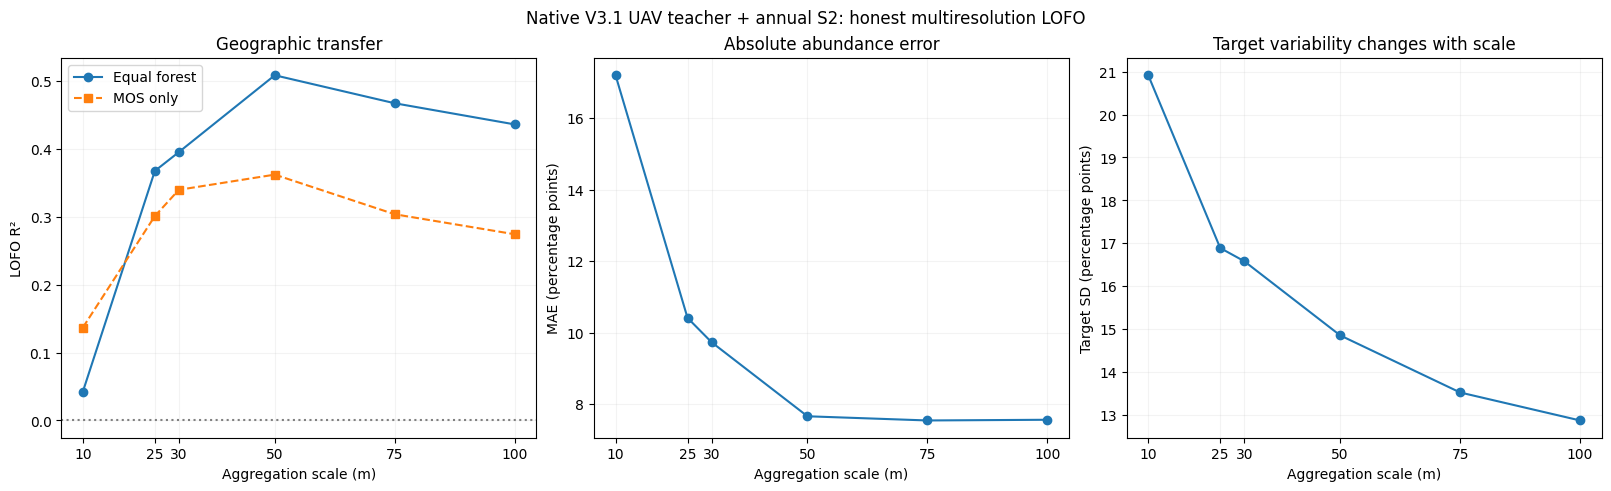

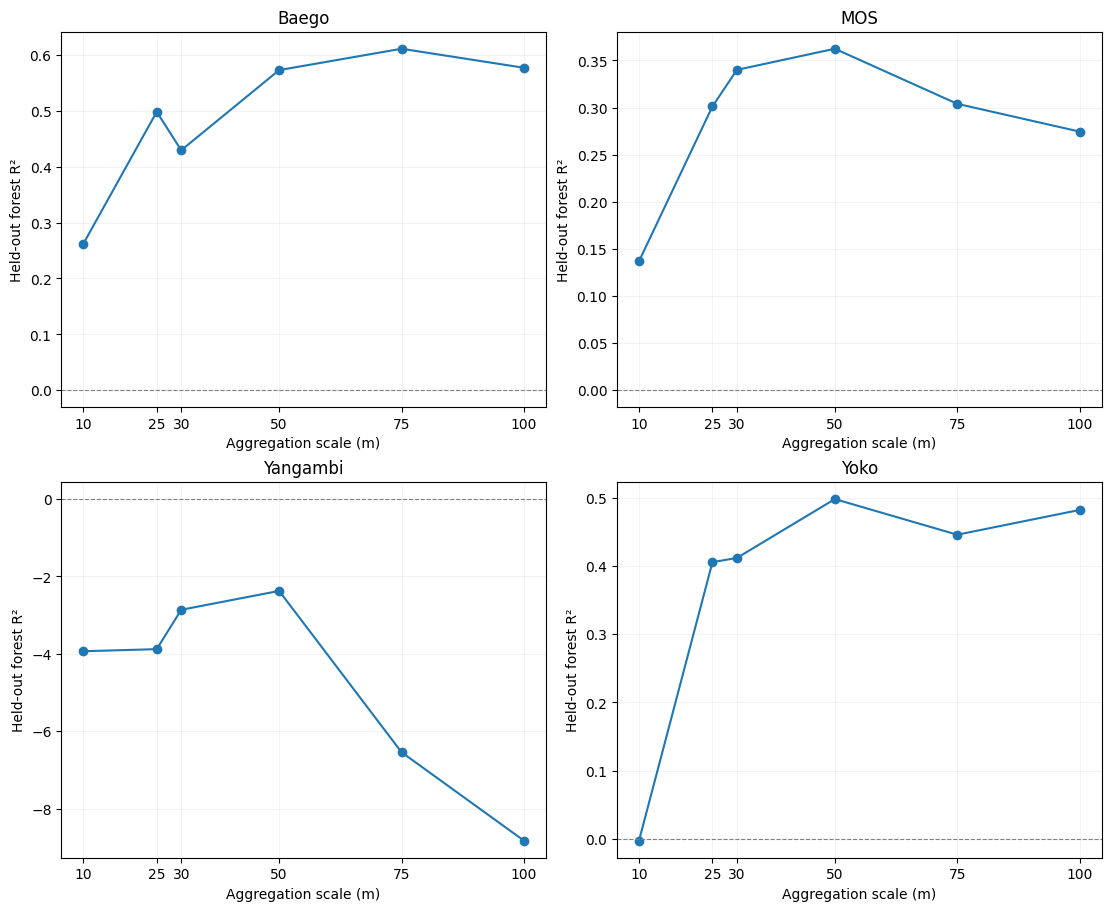

Interpretation: choose a stable resolution based on MAE, forest transfer, and ecological map utility;
avoid choosing scale by one inflated pooled R².


In [11]:
fig,ax=plt.subplots(1,3,figsize=(16,4.8),layout='constrained')
ax[0].plot(SCALE_SUM.scale_m,SCALE_SUM.equal_forest_R2,'o-',label='Equal forest')
ax[0].plot(SCALE_SUM.scale_m,SCALE_SUM.MOS_R2,'s--',label='MOS only')
ax[0].set(ylabel='LOFO R²',title='Geographic transfer')
ax[0].axhline(0,ls=':',c='grey');ax[0].legend()
ax[1].plot(SCALE_SUM.scale_m,SCALE_SUM.equal_forest_MAE_pp,'o-')
ax[1].set(ylabel='MAE (percentage points)',title='Absolute abundance error')
ax[2].plot(SCALE_SUM.scale_m,SCALE_SUM.equal_forest_target_SD_pp,'o-')
ax[2].set(ylabel='Target SD (percentage points)',title='Target variability changes with scale')
for a in ax:
 a.set_xlabel('Aggregation scale (m)')
 a.set_xticks(SCALE_SUM.scale_m.to_numpy())
 a.grid(alpha=.15)
fig.suptitle('Native V3.1 UAV teacher + annual S2: honest multiresolution LOFO')
fig.savefig(SCALE_RUN/'10_multiresolution_LOFO_three_metrics.png',dpi=180,bbox_inches='tight')
plt.show();plt.close(fig)
fig,axes=plt.subplots(2,2,figsize=(11,9),layout='constrained')
for axis,forest in zip(axes.flat,SITES):
 q=SCALE_PER[SCALE_PER.site.eq(forest)].sort_values('scale_m')
 axis.plot(q.scale_m,q.R2,'o-',label='R²')
 axis.axhline(0,ls='--',lw=.8,color='gray')
 axis.set(title=forest,xlabel='Aggregation scale (m)',ylabel='Held-out forest R²')
 axis.set_xticks(q.scale_m)
 axis.grid(alpha=.15)
fig.savefig(SCALE_RUN/'10_multiresolution_per_forest_R2.png',dpi=180,bbox_inches='tight')
plt.show();plt.close(fig)
print('Interpretation: choose a stable resolution based on MAE, forest transfer, and ecological map utility;')
print('avoid choosing scale by one inflated pooled R².')


## 11 — NICFI PlanetScope incremental information (strict 50 m matched LOFO)

The frozen 50 m reference table (built from the original 11A cached Planet inputs) contains **native PlanetScope 4.77 m B/G/R/N patch means and standard deviations**, NIR spatial texture statistics, and 10 m embedding neighbourhood means/SD. We join these columns to the *unchanged frozen 50 m target and S2* using exact `site,mosaic,row,col` keys. No raw Planet imagery is opened.

**Ablation:** annual S2 only; Planet spectral alone; Planet texture alone; annual S2 + Planet spectral; annual S2 + Planet spectral + texture; annual S2 + embedding context; all combined. Every variant in a fold uses exactly the same matched cells, forest-balanced training selection and strict held-out forest. We report per-forest R²/MAE, equal-forest R²/MAE, MOS ≥40% bias, and high-cover recall.

**Interpretation:** NICFI native pixel size is 4.77 m, but our Planet means/SD summarise roughly **100 m patches around 50 m response cells**, providing wider context. Older Planet-vs-S2 conclusions from 04B used a *Planet-only supervised model*, not identical feature families. Here we test incremental contribution of **fixed descriptive features**, not a CNN. Planet Yoko (2021) is temporally mismatched to UAV 2020.

In [12]:
# NICFI / Planet cached-feature ablation — no raster reads.
from sklearn.ensemble import HistGradientBoostingRegressor
# V3.1 NB06 Section 00 preserved every matched NICFI/context column in the
# AUTHORITATIVE frozen reference. Do not require an extra file under CLEAN_NB06.
KEYS11=['site','mosaic','row','col']
PLANET_SPEC11=[f'PLANET_{stat}_{band}' for stat in ('mean','std') for band in ('B','G','R','N')]
PLANET_TEX11=[f'PLANET_texture_{v}' for v in ('NIR_CV_r1','NIR_CV_r3','NIR_CV_r7','NIR_highpass')]
EMB_CTX11=[f'EMB_{stat}_{j:02d}' for stat in ('mean','sd') for j in range(1,65)]
NEEDED11=PLANET_SPEC11+PLANET_TEX11+EMB_CTX11
P11=ROOT/'frozen_50m_reference.parquet'
assert P11.is_file(),('Frozen reference missing; run Section 00',P11)
J11=D.copy()
missing11=sorted(set(NEEDED11)-set(J11.columns))
assert not missing11,(
 'Frozen V3.1 reference unexpectedly lacks Planet/context features; inspect',
 missing11[:30],
 'Original fallback is under ROOT.parent / 11_spatial_ablation_50m / inputs, NOT ROOT.')
assert J11[KEYS11].notna().all().all() and not J11.duplicated(KEYS11).any()
print('Using existing frozen 50m table, including NICFI/context features:',P11)
S2_ANNUAL11=[f'RAW_ANNUAL__{i:02d}' for i in range(1,15)]
PSETS11={
 'S2_annual':S2_ANNUAL11,
 'NICFI_spectral':PLANET_SPEC11,
 'NICFI_texture':PLANET_TEX11,
 'S2_plus_NICFI_spectral':S2_ANNUAL11+PLANET_SPEC11,
 'S2_plus_NICFI_all':S2_ANNUAL11+PLANET_SPEC11+PLANET_TEX11,
 'S2_plus_embedding_context':S2_ANNUAL11+EMB_CTX11,
 'S2_NICFI_embedding_context':S2_ANNUAL11+PLANET_SPEC11+PLANET_TEX11+EMB_CTX11,
}
assert set(sum(PSETS11.values(),[])).issubset(J11.columns)
complete11=np.isfinite(J11[sorted(set(sum(PSETS11.values(),[])))].to_numpy(np.float32)).all(axis=1)
J11=J11.loc[complete11].reset_index(drop=True)
assert J11.site.nunique()==4 and len(J11)>1000,('Insufficient common Planet feature cells',J11.site.value_counts().to_dict())
print('Matched Planet + S2 sample counts, identical across seven models:')
display(J11.groupby('site').target_fraction.agg(n='size',mean='mean').round(3))
OUT11=ROOT/'20_NB08_NICFI_matched_LOFO'
CFG11=dict(version='NICFI_LOFO_v4_004',source_sha=SOURCE_SHA,
 n=len(J11),keys_sha=hashlib.sha256(pd.util.hash_pandas_object(J11[KEYS11],index=False).values.tobytes()).hexdigest(),
 feature_sets=PSETS11,params=MODEL,seed=20261120,
 planet_source=dict(path=str(P11),size=P11.stat().st_size,mtime_ns=P11.stat().st_mtime_ns))
RUN11=OUT11/hashlib.sha256(json.dumps(CFG11,sort_keys=True).encode()).hexdigest()[:14]
RUN11.mkdir(parents=True,exist_ok=True)
(RUN11/'config.json').write_text(json.dumps(CFG11,indent=2))
print('NICFI output:',RUN11)


AssertionError: ('Run V3.1 NB06 Section 10 native spatial feature cache first', PosixPath('/content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/06_spatial_planet_embeddings/CLEAN_NB06/10_full_spatial_features_50m.parquet'))

In [ ]:
# Matched LOFO fits, deterministic per-forest stratified draw; saved individually.
def draw11(d,forest,cap=1500,seed=20261120):
 rng=np.random.default_rng(seed+sum(map(ord,forest)))
 ids=np.flatnonzero(d.site.to_numpy()==forest)
 if len(ids)<=cap:return ids
 values=d.target_fraction.to_numpy(float)
 strata=np.digitize(values[ids],[.1,.2,.4])
 bins={k:ids[strata==k] for k in range(4)}
 chosen=[]
 # Reserve up to 25% for high-cover cells, if available.
 q=min(len(bins[3]),int(np.ceil(cap*.25)))
 if q:
  t=rng.choice(bins[3],q,replace=False);chosen.extend(t.tolist());bins[3]=np.setdiff1d(bins[3],t)
 while len(chosen)<cap:
  active=[k for k in bins if len(bins[k])]
  assert active
  for k in active:
   nn=min(len(bins[k]),max(1,(cap-len(chosen))//len(active)),cap-len(chosen))
   if nn:
    t=rng.choice(bins[k],nn,replace=False)
    chosen.extend(t.tolist());bins[k]=np.setdiff1d(bins[k],t)
   if len(chosen)==cap:break
 return np.asarray(sorted(chosen),int)
def fit_matched_lofo(data,featuresets,out,seed=20261120):
 yv=data.target_fraction.to_numpy(float)
 forestv=data.site.to_numpy()
 per=[];preds=[]
 for held in SITES:
  test=np.flatnonzero(forestv==held)
  train_ids=np.concatenate([draw11(data,s,seed=seed) for s in SITES if s!=held])
  assert len(np.intersect1d(test,train_ids))==0
  frame=data.iloc[test][KEYS11+['target_fraction']].reset_index(drop=True).copy()
  for name,cols in featuresets.items():
   file=out/f'{held}_{name}.npz'
   if file.is_file():
    with np.load(file,allow_pickle=False) as z:
     assert np.array_equal(z['test'],test)
     yp=z['pred'].astype(float)
    print('CACHE',held,name,flush=True)
   else:
    h=HistGradientBoostingRegressor(random_state=seed,**MODEL)
    h.fit(data.iloc[train_ids][cols].to_numpy(np.float32),yv[train_ids])
    yp=np.clip(h.predict(data.iloc[test][cols].to_numpy(np.float32)),0,1)
    tmp=file.with_suffix('.partial')
    with open(tmp,'wb') as fd:np.savez_compressed(fd,test=test,pred=yp.astype(np.float32))
    os.replace(tmp,file)
    print('FIT',held,name,flush=True)
   frame[name]=yp
   err=yp-yv[test];variance=np.var(yv[test])
   hi=yv[test]>=.4
   per.append(dict(site=held,model=name,n=len(test),n_train=len(train_ids),
     MAE_pp=100*np.mean(abs(err)),RMSE_pp=100*np.sqrt(np.mean(err**2)),
     MSE=np.mean(err**2),bias_pp=100*np.mean(err),
     R2=1-np.mean(err**2)/variance if variance>0 else np.nan,
     high_n=int(hi.sum()),high_bias_pp=100*np.mean(err[hi]) if hi.any() else np.nan,
     high_recall=float(np.mean(yp[hi]>=.4)) if hi.any() else np.nan))
  preds.append(frame)
 PRED=pd.concat(preds,ignore_index=True)
 PER=pd.DataFrame(per)
 mu=PRED.groupby('site').target_fraction.mean().mean()
 variance=np.mean([np.mean((g.target_fraction.to_numpy()-mu)**2) for _,g in PRED.groupby('site')])
 SUM=[]
 for name in featuresets:
  g=PER[PER.model.eq(name)]
  SUM.append(dict(model=name,n=len(PRED),n_forests=4,
   equal_forest_R2=1-g.MSE.mean()/variance,
   equal_forest_MAE_pp=g.MAE_pp.mean(),
   equal_forest_RMSE_pp=np.sqrt(np.mean(g.RMSE_pp**2)),
   MOS_R2=float(g[g.site.eq('MOS')].R2.iloc[0]),
   MOS_high_bias_pp=float(g[g.site.eq('MOS')].high_bias_pp.iloc[0]),
   MOS_high_recall=float(g[g.site.eq('MOS')].high_recall.iloc[0])))
 SUM=pd.DataFrame(SUM)
 PER.to_csv(out/'LOFO_per_forest.csv',index=False)
 SUM.to_csv(out/'LOFO_equal_forest_summary.csv',index=False)
 PRED.to_parquet(out/'LOFO_matched_predictions.parquet',index=False)
 return PRED,PER,SUM
PRED11,PER11,SUM11=fit_matched_lofo(J11,PSETS11,RUN11)
display(SUM11.round(3))
print('Per forest:');display(PER11.pivot(index='site',columns='model',values='R2').round(3))
fig,axes=plt.subplots(1,2,figsize=(14,4.8),layout='constrained')
axes[0].bar(SUM11.model,SUM11.equal_forest_R2)
axes[0].set(title='Incremental NICFI / context transfer',ylabel='Equal-forest R²')
axes[1].bar(SUM11.model,SUM11.MOS_high_bias_pp)
axes[1].axhline(0,color='black',ls='--',lw=.8)
axes[1].set(title='MOS high-cover calibration (observed ≥40%)',ylabel='Prediction bias (pp)')
for a in axes:a.tick_params(axis='x',labelrotation=55);a.grid(axis='y',alpha=.15)
fig.savefig(RUN11/'11_NICFI_incremental_performance.png',dpi=180,bbox_inches='tight')
plt.show();plt.close(fig)


## 12 — Control for independently sourced forest height, tree cover and disturbance

The **existing cached `07A_joined_UAV_and_structure.parquet`** was sampled at a *random, forest-stratified subset* of the frozen 50 m reference centres. It includes independent products:

- **ETH global canopy height 2020** (10 m modelled height), local mean and SD;
- **JRC Tropical Moist Forest status December 2020**: undisturbed, degraded and regrowth neighbourhood fractions;
- **Copernicus 2019 tree-cover fraction** (100 m native product; not secretly 10 m).

These are imperfect **forest-condition controls**, not measured ground-truth canopy height or causal covariates. The 2020 layers can postdate Yoko's 2020 UAV acquisition or precede 2023/24 UAV dates; this is a temporal-confounding limitation.

We match the exact archived 07A sample keys and use **the same held-out observations** for (i) structure only, (ii) annual S2 only, (iii) annual S2 + structure. Incremental test: improvement in LOFO R²/MAE over structure-only indicates satellite signal beyond these *measured proxies*, not necessarily beyond true forest age/structure. If both predict similarly, ecological confounding becomes more plausible. The same complete-case sample is used across variants; no site-specific models or held-out target-informed feature selection. Results and coverage counts are always displayed.

In [ ]:
REFLECTANCE=[f'RAW_ANNUAL__{i:02d}' for i in range(1,11)]
INDICES=[f'RAW_ANNUAL__{i:02d}' for i in range(11,15)]
STRUCTURE_PATH12=ROOT/'07_structure_products_screen/07A_joined_UAV_and_structure.parquet'
assert STRUCTURE_PATH12.is_file(),('Missing cached independent forest-condition sample',STRUCTURE_PATH12)
T12=pd.read_parquet(STRUCTURE_PATH12)
STRUCT_COLS12=['height_local_mean_m','height_local_sd_m','height_model_sd_local_m',
 'tmf_undisturbed_local_frac','tmf_degraded_local_frac','tmf_regrowth_local_frac',
 'cop_2019_tree_fraction_pct']
assert set(KEYS11+STRUCT_COLS12).issubset(T12.columns),sorted(set(KEYS11+STRUCT_COLS12)-set(T12.columns))
assert not T12.duplicated(KEYS11).any()
ST12=D.merge(T12[KEYS11+STRUCT_COLS12],how='inner',on=KEYS11,validate='one_to_one')
assert len(ST12)>500 and ST12.site.nunique()==4,('Expected 4-forest independent control subset',len(ST12))
coverage12=ST12.groupby('site')[STRUCT_COLS12].agg(lambda z:100*z.notna().mean())
print('Available independent forest-condition control data, % by forest:')
display(coverage12.round(1))
ST12=ST12.dropna(subset=STRUCT_COLS12+REFLECTANCE+INDICES).reset_index(drop=True)
assert ST12.site.nunique()==4 and len(ST12)>500,('Insufficient matched structure sample',ST12.site.value_counts().to_dict())
PSETS12={
 'forest_conditions_only':STRUCT_COLS12,
 'S2_annual_only':REFLECTANCE+INDICES,
 'forest_conditions_plus_S2':STRUCT_COLS12+REFLECTANCE+INDICES}
OUT12=ROOT/'21_NB08_forest_condition_controls'
CFG12=dict(version='forest_structure_07A_LOFO_v4_004',source_sha=SOURCE_SHA,
  key_sha=hashlib.sha256(pd.util.hash_pandas_object(ST12[KEYS11],index=False).values.tobytes()).hexdigest(),
  n=len(ST12),features=PSETS12,
  sample_source=dict(path=str(STRUCTURE_PATH12),size=STRUCTURE_PATH12.stat().st_size,
                     mtime_ns=STRUCTURE_PATH12.stat().st_mtime_ns),
  sampling='Independent 2019-2020 forest structure proxies at 50m cell centres; native 100m tree cover')
RUN12=OUT12/hashlib.sha256(json.dumps(CFG12,sort_keys=True).encode()).hexdigest()[:14]
RUN12.mkdir(parents=True,exist_ok=True)
(RUN12/'config.json').write_text(json.dumps(CFG12,indent=2))
print('Matched control data by forest:');display(ST12.groupby('site').size().rename('n'))
PRED12,PER12,SUM12=fit_matched_lofo(ST12,PSETS12,RUN12)
display(SUM12.round(3))
display(PER12.pivot(index='site',columns='model',values='R2').round(3))
fig,ax=plt.subplots(1,2,figsize=(12,4.8),layout='constrained')
ax[0].bar(SUM12.model,SUM12.equal_forest_R2);ax[0].set(ylabel='Equal-forest R²',title='Independent structure control')
ax[1].bar(SUM12.model,SUM12.equal_forest_MAE_pp);ax[1].set(ylabel='MAE (pp)',title='Forest-equal absolute error')
for a in ax:a.tick_params(axis='x',labelrotation=18);a.grid(axis='y',alpha=.15)
fig.savefig(RUN12/'12_structure_control_incremental_LOFO.png',dpi=180,bbox_inches='tight')
plt.show();plt.close(fig)
print('Caution: temporal and native-resolution mismatch; a proxy-only model is not evidence of causal identification.')


## 13 — Separate UAV DSM sensitivity: *relative surface shape*, not canopy height

An existing archived 16B DSM analysis measures `roughness_sd_m` and `relative_surface_m` in and around frozen 50 m cells. These variables depend on terrain, sensor geometry and reconstruction quality. Crucially, **DSM ≠ canopy-height model (CHM)**; no digital terrain model is used. The 16B DSM covers only **MOS_1_2**, not MOS_5_6, so sample availability is geographically uneven.

**Purpose:** exploratory matched LOFO comparison of annual S2 versus S2+DSM roughness on the valid 16B subset. It may fail the 4-forest support requirement; in that case this block stops with a clear diagnostic rather than substituting missing values or misrepresenting the limited sample. Do not combine this subset's metrics with the primary NICFI comparison.

In [ ]:
DSM_PATH13=ROOT/'16_DSM_structure/16B_reference_cells/16B_frozen_cells_DSM_metrics.parquet'
assert DSM_PATH13.is_file(),('Cached DSM diagnostic missing',DSM_PATH13)
DSM13=pd.read_parquet(DSM_PATH13)
DSM_COLS13=['roughness_sd_m','relative_surface_m','ring_residual_sd_m','ring_slope_m_per_m']
assert set(KEYS11+DSM_COLS13).issubset(DSM13.columns)
assert not DSM13.duplicated(KEYS11).any()
DS13=D.merge(DSM13[KEYS11+DSM_COLS13],on=KEYS11,how='inner',validate='one_to_one')
DS13=DS13.replace([np.inf,-np.inf],np.nan).dropna(subset=DSM_COLS13+REFLECTANCE+INDICES).reset_index(drop=True)
print('Valid DSM-matched sample by forest:');display(DS13.groupby('site').size().reindex(SITES,fill_value=0))
if set(DS13.site.unique())!=set(SITES) or DS13.groupby('site').size().min()<30:
 print('DSM subset is not suitable for a full 4-forest LOFO claim. Descriptive association only; no model fitted.')
else:
 PSETS13={'S2_annual':REFLECTANCE+INDICES,
   'DSM_relative_surface_only':DSM_COLS13,
   'S2_plus_DSM_surface':REFLECTANCE+INDICES+DSM_COLS13}
 OUT13=ROOT/'22_NB08_DSM_exploratory_control'
 CFG13=dict(version='DSM_exploratory_v4_004',source_sha=SOURCE_SHA,
   keys_sha=hashlib.sha256(pd.util.hash_pandas_object(DS13[KEYS11],index=False).values.tobytes()).hexdigest(),
   features=PSETS13,n=len(DS13),dsm_mtime=DSM_PATH13.stat().st_mtime_ns)
 RUN13=OUT13/hashlib.sha256(json.dumps(CFG13,sort_keys=True).encode()).hexdigest()[:14]
 RUN13.mkdir(parents=True,exist_ok=True)
 (RUN13/'config.json').write_text(json.dumps(CFG13,indent=2))
 PRED13,PER13,SUM13=fit_matched_lofo(DS13,PSETS13,RUN13)
 display(SUM13.round(3))
 fig,ax=plt.subplots(figsize=(8,4.5),layout='constrained')
 ax.bar(SUM13.model,SUM13.equal_forest_R2)
 ax.tick_params(axis='x',rotation=18);ax.set(ylabel='Equal-forest R²',title='DSM relative surface / roughness (exploratory)')
 fig.savefig(RUN13/'13_DSM_matched_LOFO.png',dpi=180)
 plt.show();plt.close(fig)
print('NB08 v4_004 complete. Original validated experiments and output folders were not modified.')
